# Explore SWE observation-to-model quantile mapping

This notebook preprocesses point SWE observations into **model-equivalent** SWE. It does **not** bias-correct the model, alter the model state, or run data assimilation. The transformation direction is always observation space → model space.

$$
 y_{\mathrm{model\_equiv}}
 =
 F_{\mathrm{mod}}^{-1}\bigl(F_{\mathrm{obs}}(y_{\mathrm{obs}})\bigr)
$$

The observed climatological rank is preserved; the value is rewritten in the model's SWE climatology so it can later be compared directly to the model state.

## Step-by-step remapping

### 1. Align the two records in time, without filling gaps

Observations are daily NorSWE `snw` at each `station_id`. Modeled SWE is SUMMA `scalarSWE`, which is ~hourly. For each observation date we take only the **00:00** model value. There is no daily mean and no interpolation. If midnight is missing, that date is unpaired (`swe_model` is NaN).

The Ross run is lumped (one HRU), so every station is colocated with that same midnight series.

Before inventory and mapping, the two Twin Creeks snow surveys (`CanSWE-YT-09BA-SC02A` and `CanSWE-YT-09BA-SC02B`) are combined into one record (`CanSWE-YT-09BA-SC02`, name `TWIN CREEKS combined`). Dates with a value at only one survey keep that value; the six overlapping dates use the **arithmetic mean**. Missing days are not interpolated. That pooling is an explicit observation-preprocessing step. After it, quantile mapping remains station-specific: each remaining station (combined SC02, M5, M7) gets its own $F_{\mathrm{obs}}$ and $F_{\mathrm{mod}}$.

### 2. Decide what to do with this observation

For each station and each date:

1. Missing or negative observed SWE → no mapped value (`mapping_flag = 3`).
2. Observed SWE exactly **zero** → model-equivalent is **zero**. Quantile mapping is not applied. Snow-on / snow-off timing is not adjusted.
3. Observed SWE **positive** → continue to seasonal quantile mapping.

### 3. Build a seasonal calibration sample

Snow SWE is strongly seasonal, so we do not use one annual distribution.

For a target date, collect historical pairs whose **calendar day-of-year** is within $\pm$ `window_days` (default 30) of the target, using circular distance so 1 October includes late September:

$$
 \min\bigl(|d_1-d_2|,\, 366-|d_1-d_2|\bigr) \le \texttt{window\_days}.
$$

Only dates where **both** observed and midnight model SWE are finite enter the sample. Nothing is gap-filled.

If `cross_validate=True` (the default), drop every pair from the target **water year** (1 October start: 1 Oct 2015 is water year 2016). The target year does not help define its own mapping.

Then keep only pairs where **both** values are strictly positive. Zeros stay in the zero rule above; they do not enter $F_{\mathrm{obs}}$ or $F_{\mathrm{mod}}$.

If fewer than `min_samples` (default 20) positive pairs remain, the mapped value is missing (`mapping_flag = 2`). The window is not widened and other stations are not borrowed.

### 4. Estimate two empirical distributions

From those positive pairs, form two **independent** samples: the observed values and the modeled values. They share dates, but they are **sorted separately**. We do not regress obs on model, and we do not match pair-by-pair.

Sort each sample and assign Hazen plotting positions

$$
 p_i = \frac{i - 0.5}{n}, \qquad i = 1,\ldots,n.
$$

Tied SWE values are collapsed to one unique value with the **mean** plotting position of the tie, so the quantile grid is strictly increasing. Linear interpolation is used between those empirical quantiles. No parametric distribution is fitted.

### 5. Map the observation through those distributions

1. Find the observation's percentile in the observed CDF: $q = F_{\mathrm{obs}}(y_{\mathrm{obs}})$.
2. If $y_{\mathrm{obs}}$ is below (above) the calibration range, clip $q$ to the smallest (largest) supported plotting position. Tails are not extrapolated.
3. Read the model quantile function at that same percentile: $y_{\mathrm{model\_equiv}} = F_{\mathrm{mod}}^{-1}(q)$.

A high observation relative to the station's own winter climatology becomes a high value relative to the model's winter climatology, even if the two SWE scales differ.

### 6. Write the result beside the original observation

The original `snw` is kept. New fields include `swe_obs`, `swe_model_equivalent`, `quantile_obs`, `n_samples_mapping`, and `mapping_flag`.

Stations are also screened by how many **water years** have data (`MIN_YEARS`, default 5). Short records are still mapped for inspection and marked `passes_year_screen = False`.


In [1]:
from pathlib import Path

%load_ext autoreload
%autoreload 2
%matplotlib inline

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from snowda.obs_qm import (
    FLAG_INSUFFICIENT_SAMPLES,
    FLAG_MAPPED,
    FLAG_MISSING_OBS,
    FLAG_ZERO_OBS,
    attach_mapped_variables,
    combine_stations,
    pair_obs_model,
    plot_station_diagnostics,
    preprocess_all_stations,
    station_record_table,
    stations_to_plot,
    read_midnight_model_swe,
    read_swe_observations,
    write_mapped_observations,
)

OBS_PATH = Path("/Users/dcasson/Data/snow_data/NorSWE/Ross_Lumped_NorSWE.nc")
MODEL_PATH = Path(
    "/Users/dcasson/GitHub/snowda/outputs/ross_summa_deterministic/"
    "20260916T223844Z/summa/001_2022_09_30_timestep.nc"
)
OUT_DIR = Path("/Users/dcasson/GitHub/snowda/outputs/obs_qm")
OUT_NC = OUT_DIR / "ross_norswe_model_equivalent.nc"

WINDOW_DAYS = 30
MIN_SAMPLES = 20
MIN_YEARS = 10
CROSS_VALIDATE = True
PLOT_SCREENED = False

## Observation inventory

NorSWE `snw` is daily point SWE (`kg m-2`) at `station_id`. Finite values can be sparse (surveys vs pillows).

The two Twin Creeks surveys are merged first (mean on overlapping dates). Inventory, pairing, and mapping then see three stations: combined SC02, M5, and M7.

Screen stations by **water years with at least one finite observation** (`MIN_YEARS`). Short records remain in the maps and netCDF and are marked `passes_year_screen = False`; they are not plotted unless `PLOT_SCREENED` is `True`.

In [3]:
obs_ds = read_swe_observations(OBS_PATH)
obs_ds = combine_stations(
    obs_ds,
    ["CanSWE-YT-09BA-SC02A", "CanSWE-YT-09BA-SC02B"],
    new_id="CanSWE-YT-09BA-SC02",
    new_name="TWIN CREEKS combined",
)
snw = obs_ds["snw"]
print(obs_ds)
print()
print("time:", obs_ds.time.values[0], "->", obs_ds.time.values[-1])

coverage = station_record_table(snw, min_years=MIN_YEARS)
rows = []
for sid in obs_ds.station_id.values:
    v = snw.sel(station_id=sid).values
    finite = np.isfinite(v)
    cov = coverage.set_index("station_id").loc[sid]
    rows.append(
        {
            "station_id": sid,
            "name": str(obs_ds["station_name"].sel(station_id=sid).values),
            "elevation_m": float(obs_ds["elevation"].sel(station_id=sid)),
            "n_finite": int(finite.sum()),
            "n_zero": int(((v == 0) & finite).sum()),
            "n_positive": int((v > 0).sum()),
            "n_calendar_years": int(cov["n_calendar_years"]),
            "n_water_years": int(cov["n_water_years"]),
            "first_year": cov["first_year"],
            "last_year": cov["last_year"],
            "passes_year_screen": bool(cov["passes_year_screen"]),
            "min": float(np.nanmin(v)) if finite.any() else np.nan,
            "max": float(np.nanmax(v)) if finite.any() else np.nan,
        }
    )
pd.DataFrame(rows)

<xarray.Dataset> Size: 1MB
Dimensions:        (station_id: 3, time: 15706)
Coordinates:
  * time           (time) datetime64[ns] 126kB 1979-01-01 ... 2021-12-31
  * station_id     (station_id) object 24B 'CanSWE-YT-09BA-M5' ... 'CanSWE-YT...
Data variables: (12/14)
    lat            (station_id) float64 24B 62.62 62.62 62.62
    lon            (station_id) float64 24B -131.3 -131.3 -131.3
    elevation      (station_id) float64 24B 893.8 886.4 900.0
    source         (station_id) <U24 288B 'CanSWEv6-Yukon Territory' ... 'Can...
    station_name   (station_id) <U20 240B 'TWIN CREEKS A' ... 'TWIN CREEKS co...
    type_mes       (station_id) float64 24B 2.0 2.0 0.0
    ...             ...
    snd            (time, station_id) float32 188kB nan nan nan ... nan nan nan
    den            (time, station_id) float32 188kB nan nan nan ... nan nan nan
    data_flag_snw  (time, station_id) <U1 188kB '' '' '' '' '' ... '' '' '' ''
    data_flag_snd  (time, station_id) <U1 188kB '' '' '' '' '' .

,station_id,name,elevation_m,n_finite,n_zero,n_positive,n_calendar_years,n_water_years,first_year,last_year,passes_year_screen,min,max
0,CanSWE-YT-09BA-M5,TWIN CREEKS A,893.799988,1683,38,1645,9,8,1988.0,1996.0,False,0.0,231.0
1,CanSWE-YT-09BA-M7,TWIN CREEKS B,886.400024,528,6,522,3,3,2019.0,2021.0,False,0.0,216.0
2,CanSWE-YT-09BA-SC02,TWIN CREEKS combined,900.000000,150,11,139,43,43,1979.0,2021.0,True,0.0,277.0


## Midnight model SWE

SUMMA `scalarSWE` is ~hourly. Pairing uses the **00:00** instantaneous value only. Days without a midnight sample stay unpaired (no averaging, no interpolation). The Ross file is lumped (one HRU), so every station is colocated with that HRU.

In [4]:
model = read_midnight_model_swe(MODEL_PATH)
print(model)
print("midnight time:", model.time.values[0], "->", model.time.values[-1])
print("n midnight days:", model.sizes["time"])
print("units:", model.attrs.get("units"))
print("min/max:", float(model.min()), float(model.max()))

<xarray.DataArray 'swe_model' (time: 15370)> Size: 123kB
array([5.76731984, 3.19113383, 3.01179331, ..., 0.        , 0.        ,
       0.        ], shape=(15370,))
Coordinates:
    hru      int32 4B 1
  * time     (time) datetime64[ns] 123kB 1980-09-01 1980-09-02 ... 2022-09-30
Attributes:
    long_name:             snow water equivalent (instant)
    units:                 kg m-2
    model_time_selection:  midnight
    midnight_tolerance:    0 days 00:01:00
    source:                /Users/dcasson/GitHub/snowda/outputs/ross_summa_de...
    model_variable:        scalarSWE
midnight time: 1980-09-01T00:00:00.000000000 -> 2022-09-30T00:00:00.000000000
n midnight days: 15370
units: kg m-2
min/max: 0.0 253.30240200327816


In [5]:
pair_rows = []
for sid in obs_ds.station_id.values:
    paired = pair_obs_model(snw.sel(station_id=sid), model)
    obs_finite = np.isfinite(paired["swe_obs"].values)
    pair_rows.append(
        {
            "station_id": sid,
            "n_obs_times": int(paired.attrs["n_obs_times"]),
            "n_obs_finite": int(obs_finite.sum()),
            "n_paired": int(paired.attrs["n_paired"]),
            "n_finite_obs_missing_midnight": int(
                paired.attrs["n_unpaired_missing_model"]
            ),
        }
    )
pd.DataFrame(pair_rows)

,station_id,n_obs_times,n_obs_finite,n_paired,n_finite_obs_missing_midnight
0,CanSWE-YT-09BA-M5,15706,1683,1683,0
1,CanSWE-YT-09BA-M7,15706,528,528,0
2,CanSWE-YT-09BA-SC02,15706,150,141,9


## Map observations into model space

Each station is mapped independently. Default cross-validation leaves out the target water year (1 October start) when building $F_{\mathrm{obs}}$ and $F_{\mathrm{mod}}$.

In [6]:
mapped = preprocess_all_stations(
    snw,
    model,
    window_days=WINDOW_DAYS,
    min_samples=MIN_SAMPLES,
    min_years=MIN_YEARS,
    cross_validate=CROSS_VALIDATE,
)
mapped

<xarray.Dataset> Size: 2MB
Dimensions:                 (station_id: 3, time: 15706)
Coordinates:
  * station_id              (station_id) object 24B 'CanSWE-YT-09BA-M5' ... '...
  * time                    (time) datetime64[ns] 126kB 1979-01-01 ... 2021-1...
Data variables: (12/17)
    swe_obs                 (station_id, time) float64 377kB nan nan ... nan nan
    swe_model               (station_id, time) float64 377kB nan nan ... 93.83
    swe_model_equivalent    (station_id, time) float64 377kB nan nan ... nan nan
    quantile_obs            (station_id, time) float64 377kB nan nan ... nan nan
    n_samples_mapping       (station_id, time) int32 188kB 0 0 0 0 0 ... 0 0 0 0
    mapping_flag            (station_id, time) int8 47kB 3 3 3 3 3 ... 3 3 3 3 3
    ...                      ...
    n_calendar_years        (station_id) float64 24B 9.0 3.0 43.0
    n_water_years           (station_id) float64 24B 8.0 3.0 43.0
    n_water_years_positive  (station_id) float64 24B 8.0 3.0 43.0
    first_year              (station_id) float64 24B 1.988e+03 ... 1.979e+03
    last_year               (station_id) float64 24B 1.996e+03 ... 2.021e+03
    passes_year_screen      (station_id) bool 3B False False True
Attributes:
    mapping_method:          empirical_quantile_mapping
    mapping_direction:       observation_to_model
    seasonal_window_days:    30
    cross_validation:        leave_one_water_year_out
    min_samples:             20
    water_year_start_month:  10
    plotting_position:       hazen_(i-0.5)/n
    model_time_selection:    midnight
    min_years:               10
    station_pooling:         none

In [7]:
flag_names = {
    int(FLAG_MAPPED): "mapped",
    int(FLAG_ZERO_OBS): "zero_obs",
    int(FLAG_INSUFFICIENT_SAMPLES): "insufficient_samples",
    int(FLAG_MISSING_OBS): "missing_obs",
}
summary = []
for sid in mapped.station_id.values:
    sub = mapped.sel(station_id=sid)
    flags, counts = np.unique(sub["mapping_flag"].values, return_counts=True)
    row = {
        "station_id": sid,
        "n_paired": float(sub["n_paired"]),
        "n_water_years": int(sub["n_water_years"]),
        "passes_year_screen": bool(sub["passes_year_screen"]),
        "obs_zero_fraction": float(sub["obs_zero_fraction"]),
        "model_zero_fraction": float(sub["model_zero_fraction"]),
        "both_positive_fraction": float(sub["both_positive_fraction"]),
    }
    for flag, n in zip(flags, counts):
        row[flag_names.get(int(flag), str(int(flag)))] = int(n)
    summary.append(row)
pd.DataFrame(summary).fillna(0)

,station_id,n_paired,n_water_years,passes_year_screen,obs_zero_fraction,model_zero_fraction,both_positive_fraction,mapped,zero_obs,missing_obs
0,CanSWE-YT-09BA-M5,1683.0,8,False,0.022579,0.002377,0.975639,1645,38,14023
1,CanSWE-YT-09BA-M7,528.0,3,False,0.011364,0.001894,0.988636,522,6,15178
2,CanSWE-YT-09BA-SC02,141.0,43,True,0.070922,0.014184,0.929078,139,11,15556


## Station diagnostics

One figure per station that **passes the year screen**: four comparison panels (positive SWE distributions; observed vs model-equivalent and same-day model vs mapped obs, both coloured by held-out water year; Q-Q of mapped obs vs model climatology) and a full-width timeseries of model SWE, observations, and observations in model space.

Screened stations stay in the tables and netCDF. Set `PLOT_SCREENED = True` to draw them too. Sparse survey windows with `insufficient_samples` are expected; that is not a silent fallback.

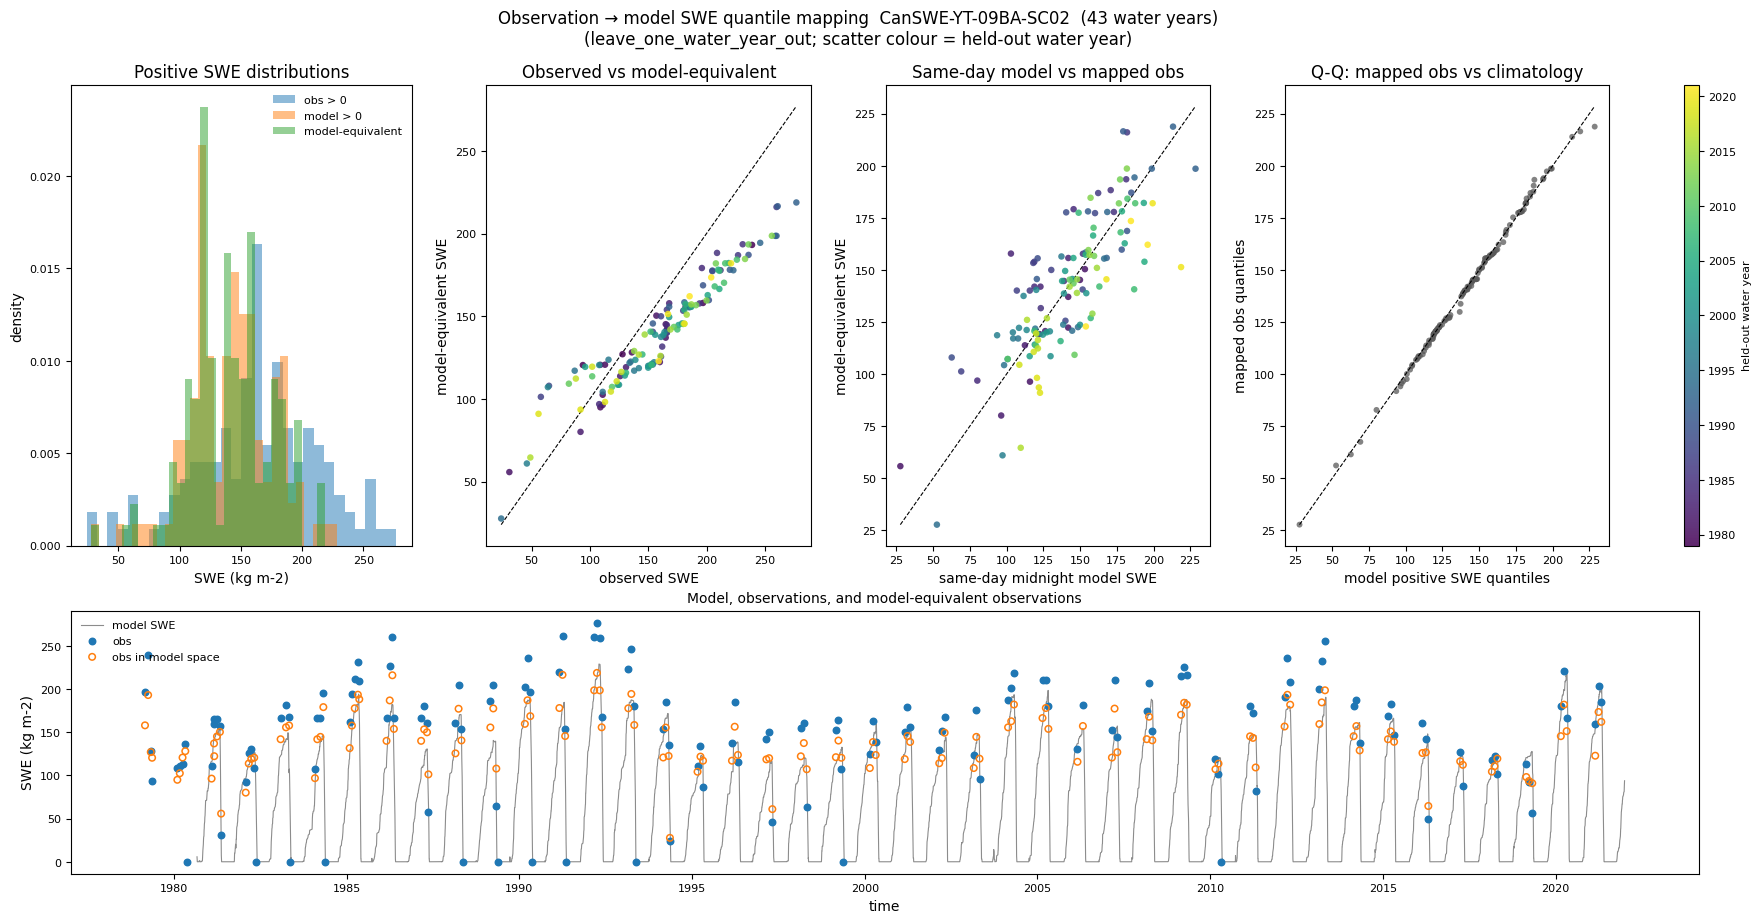

In [8]:
figures = []
for sid in stations_to_plot(mapped, include_screened=PLOT_SCREENED):
    fig = plot_station_diagnostics(mapped, station_id=sid)
    figures.append(fig)
    plt.show()

## Transformation check (not skill)

Among **mapped positive** values, compare the transformed sample to the colocated midnight model SWE on paired positive dates. Leave-one-year-out, zeros, and clipping mean this will not match $F_{\mathrm{mod}}$ exactly. It only checks that the transformation lands in model climatology space.

In [9]:
qq_rows = []
for sid in mapped.station_id.values:
    sub = mapped.sel(station_id=sid)
    mapped_mask = np.asarray(sub["mapping_flag"].values) == FLAG_MAPPED
    y_star = np.asarray(sub["swe_model_equivalent"].values)[mapped_mask]
    y_star = y_star[np.isfinite(y_star)]
    paired = np.asarray(sub["paired"].values)
    obs = np.asarray(sub["swe_obs"].values)
    model_vals = np.asarray(sub["swe_model"].values)
    model_pos = model_vals[paired & (obs > 0) & (model_vals > 0)]
    if y_star.size == 0 or model_pos.size == 0:
        qq_rows.append(
            {
                "station_id": sid,
                "n_mapped": int(y_star.size),
                "n_model_positive": int(model_pos.size),
                "mean_transformed": np.nan,
                "mean_model_positive": np.nan,
                "median_transformed": np.nan,
                "median_model_positive": np.nan,
            }
        )
        continue
    qq_rows.append(
        {
            "station_id": sid,
            "n_mapped": int(y_star.size),
            "n_model_positive": int(model_pos.size),
            "mean_transformed": float(np.mean(y_star)),
            "mean_model_positive": float(np.mean(model_pos)),
            "median_transformed": float(np.median(y_star)),
            "median_model_positive": float(np.median(model_pos)),
        }
    )
pd.DataFrame(qq_rows)

,station_id,n_mapped,n_model_positive,mean_transformed,mean_model_positive,median_transformed,median_model_positive
0,CanSWE-YT-09BA-M5,1645,1642,108.044974,109.048228,109.601881,110.139884
1,CanSWE-YT-09BA-M7,522,522,108.059924,109.138944,114.761117,118.618795
2,CanSWE-YT-09BA-SC02,139,131,141.179568,141.746430,141.940225,142.029157


## Write mapped observations

The original NorSWE variables are preserved. New fields are added alongside `snw`.

In [10]:
out_ds = attach_mapped_variables(obs_ds, mapped, obs_variable="snw")
written = write_mapped_observations(out_ds, OUT_NC)
print("wrote", written)
print("variables:", list(out_ds.data_vars))
print("mapping_method:", out_ds.attrs.get("mapping_method"))
print("mapping_direction:", out_ds.attrs.get("mapping_direction"))
print("seasonal_window_days:", out_ds.attrs.get("seasonal_window_days"))
print("cross_validation:", out_ds.attrs.get("cross_validation"))
obs_ds.close()

wrote /Users/dcasson/GitHub/snowda/outputs/obs_qm/ross_norswe_model_equivalent.nc
variables: ['lat', 'lon', 'elevation', 'source', 'station_name', 'type_mes', 'mmask', 'snw', 'snd', 'den', 'data_flag_snw', 'data_flag_snd', 'qc_flag_snw', 'qc_flag_snd', 'swe_obs', 'swe_model', 'swe_model_equivalent', 'quantile_obs', 'n_samples_mapping', 'mapping_flag', 'paired', 'n_paired', 'obs_zero_fraction', 'model_zero_fraction', 'both_positive_fraction', 'n_calendar_years', 'n_water_years', 'n_water_years_positive', 'first_year', 'last_year', 'passes_year_screen']
mapping_method: empirical_quantile_mapping
mapping_direction: observation_to_model
seasonal_window_days: 30
cross_validation: leave_one_water_year_out


/Users/dcasson/GitHub/snowda/src/snowda/obs_qm/io.py:148: SerializationWarning: saving variable type_mes with floating point data as an integer dtype without any _FillValue to use for NaNs
  ds.to_netcdf(out_path)
/Users/dcasson/GitHub/snowda/src/snowda/obs_qm/io.py:148: SerializationWarning: saving variable mmask with floating point data as an integer dtype without any _FillValue to use for NaNs
  ds.to_netcdf(out_path)
